# <div style="color:#fff;display:fill;border-radius:10px;background-color:#004F98;text-align:center;letter-spacing:0.1px;overflow:hidden;padding:20px;color:white;overflow:hidden;margin:0;font-size:100%">📊 Online Retail Sales Analysis</div>

# Online Retail — Full Data Analysis Project
### Pandas • Matplotlib • Seaborn • Plotly


**Dataset source:** [Online Retail Dataset — Kaggle](https://www.kaggle.com/datasets/vijayuv/onlineretail)

**Dataset facts:** The commonly distributed version contains approximately 541,909 transaction rows and fields such as invoice number, product code, description, quantity, invoice date, unit price, customer ID, and country. Your downloaded file may differ slightly, so always inspect it rather than assuming exact counts.



---

## 0. Environment setup and dataset loading

You can download the dataset through KaggleHub. If Kaggle authentication or package access is unavailable, download the dataset manually from the Kaggle page and update the file path below.

**Expected source file:** The original Online Retail dataset is commonly distributed as an Excel file (`.xlsx`). Your Kaggle copy may provide a CSV instead.

# 1- Import important Libraries

In [1]:
import pandas as pd
import numpy  as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns' , None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('Libraries imported Successfully')

Libraries imported Successfully


# 2-  Reading The Data

In [2]:
data=pd.read_csv('OnlineRetail.csv' , encoding='latin1' , parse_dates= ['InvoiceDate'])
df = data.copy()

print('Data Loaded ')

Data Loaded 


---

# Part 1 — Data Understanding & Initial Inspection (Questions 1–5)

### Q1. First look
Display the first 10 rows and last 10 rows. Based on the columns, explain what one row represents.

### Q2. Dataset dimensions
Find the number of rows and columns. Calculate the memory usage of the DataFrame and identify whether the dataset is large enough to require careful memory handling.

### Q3. Schema inspection
Display column names, data types, and non-null counts. Which columns have incorrect or unexpected data types?

### Q4. Statistical overview
Generate descriptive statistics for numeric and categorical columns separately. Write down at least three observations.

### Q5. Cardinality check
For each column, calculate the number of unique values. Identify columns that behave like identifiers and columns that represent categories.

In [3]:
display('The first 10 Rows :' , df.head(10))
display('The Last 10 Rows :' , df.tail(10))

# InvoiceNo : Unique invoice/transaction number. Identifies a purchase transaction.
# StockCode : Unique product code identifying the item
# Description : description of the product.
# Quantity : Number of units purchased in that transaction.
# InvoiceDate : Date and Time when the transaction occurred.
# UnitPrice : Price of one unit of the product.
# CustomerID : Unique identifier assigned to each customer.
# Country : Country where the customer is located.

'The first 10 Rows :'

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,"17,850.00",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,"17,850.00",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,"13,047.00",United Kingdom


'The Last 10 Rows :'

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,"12,680.00",France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,"12,680.00",France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,2011-12-09 12:50:00,1.95,"12,680.00",France
541902,581587,22629,SPACEBOY LUNCH BOX,12,2011-12-09 12:50:00,1.95,"12,680.00",France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,"12,680.00",France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France


# 3- Shape of the Data

In [4]:
rows , columns = df.shape

print(f'Number of rows : {rows:,}')
print(f'Number of Columns : {columns:,}')


Number of rows : 541,909
Number of Columns : 8


In [5]:
print('Column Names are : ' , df.columns.to_list())

Column Names are :  ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


# Check Data Types

In [6]:
df.dtypes

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

# data Information

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 59.5 MB


# Summary Statistical

In [8]:
print('Summary Statistical for Numerical :')
df.describe()

# quantity has Invalid data {min -80 and max 80995}
# UnitPrice has Invalid data {min -11 and (max 38970 for check)}

Summary Statistical for Numerical :


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


In [9]:
print('Summary Statistical for Categorical :')
df.describe(include='O')



Summary Statistical for Categorical :


C:\Users\hazem\AppData\Local\Temp\ipykernel_20880\496833459.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='O')


,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


# Check Cardinality

In [10]:
for col in df.columns:
    print(col)
    print(df[col].nunique())


InvoiceNo
25900
StockCode
4070
Description
4223
Quantity
722
InvoiceDate
23260
UnitPrice
1630
CustomerID
4372
Country
38


---

# Part 2 — Data Quality Investigation (Questions 6–13)

### Q6. Missing values report
Calculate the missing-value count and missing-value percentage for every column. Sort the report by missing percentage.

### Q7. Missingness visualization
Create a visualization showing the distribution or pattern of missing values. Which columns are most affected?

### Q8. Duplicate investigation
Count fully duplicated rows. Display a sample of duplicates and investigate whether they are exact repeated records.

### Q9. Invoice and cancellation analysis
Inspect `InvoiceNo`. Identify cancellation invoices (commonly invoices whose number starts with `C`). Count them and calculate their share of all rows.

### Q10. Quantity validation
Investigate zero and negative values in `Quantity`. Are negative quantities necessarily errors? Explain how they may relate to returns or cancellations.

### Q11. Unit price validation
Investigate zero and negative values in `UnitPrice`. Count affected records and inspect examples before deciding how to handle them.

### Q12. Product description quality
Inspect missing and repeated values in `Description`. Identify whether product codes appear with multiple descriptions.

### Q13. Customer and country quality
Investigate missing `CustomerID` values and inspect the distribution of `Country`. Decide which analyses can be performed without customer IDs.

# Check Missing Values

In [11]:
missing =df.isna().sum().sort_values(ascending=False)

display(missing[missing > 0].to_frame('Missing_values'))

,Missing_values
CustomerID,135080
Description,1454


# Missing Values Percentage

In [12]:
missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)

display(missing_pct[missing_pct > 0].to_frame('Missing%'))

,Missing%
CustomerID,24.93
Description,0.27


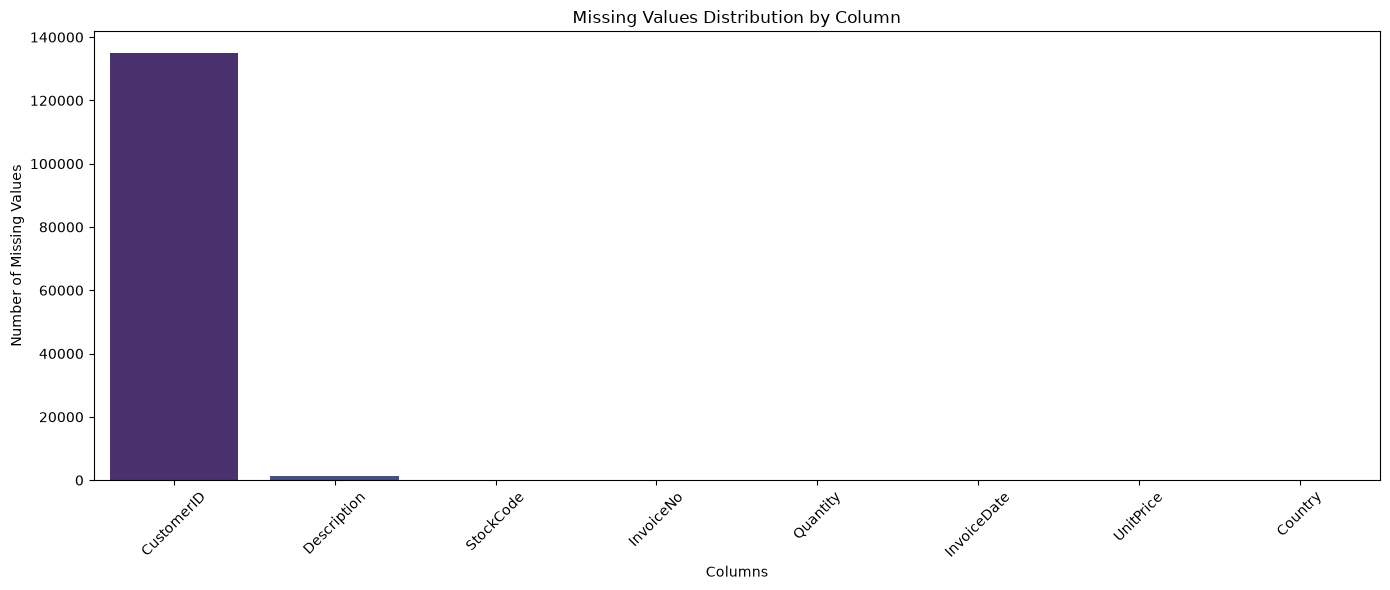

In [13]:
plt.figure(figsize=(14,6))
sns.barplot(x=missing.index,
            y = missing.values,
            hue = missing.index,
            palette='viridis',
            legend = False)
plt.title('Missing Values Distribution by Column')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Insight: Identify the columns with the highest number of missing values.

In [14]:
df[df['UnitPrice'] > 10000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,"13,541.33",NaN,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,"13,541.33",NaN,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,"13,474.79",NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,"13,541.33",NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,"16,888.02",NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,"16,453.71",NaN,United Kingdom
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,"38,970.00","15,098.00",United Kingdom
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom
524601,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,"11,586.50",NaN,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,"17,836.46",NaN,United Kingdom


# check Duplicates

In [15]:
duplicates_rows=df.duplicated().sum()

print(f"Duplicate rows: {duplicates_rows:,}")

duplicates = df[df.duplicated(keep=False)]

duplicates.sample(min(500,len(duplicates)),random_state=42)

Duplicate rows: 5,268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
521294,580358,23498,CLASSIC BICYCLE CLIPS,1,2011-12-02 16:07:00,1.45,"17,238.00",United Kingdom
189208,553141,22907,PACK OF 20 NAPKINS PANTRY DESIGN,1,2011-05-13 13:01:00,0.85,"15,907.00",United Kingdom
388283,570423,20728,LUNCH BAG CARS BLUE,2,2011-10-10 13:38:00,1.65,"14,451.00",United Kingdom
385700,570211,23330,DECORATIVE WICKER HEART MEDIUM,1,2011-10-09 11:15:00,1.25,"13,558.00",United Kingdom
151072,549537,22860,EASTER TIN CHICKS PINK DAISY,1,2011-04-08 17:22:00,1.65,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
503631,578929,82483,WOOD 2 DRAWER CABINET WHITE FINISH,2,2011-11-27 12:31:00,6.95,"13,064.00",United Kingdom
186057,552843,21181,PLEASE ONE PERSON METAL SIGN,1,2011-05-11 14:37:00,2.10,"14,649.00",United Kingdom
301094,563239,23205,CHARLOTTE BAG VINTAGE ALPHABET,1,2011-08-15 10:02:00,0.85,"15,048.00",United Kingdom
118916,546502,22429,ENAMEL MEASURING JUG CREAM,1,2011-03-14 11:46:00,4.25,"16,005.00",United Kingdom


In [16]:
duplicate_groups = (
    df.groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name='Occurrences')
)

duplicate_groups = duplicate_groups[
    duplicate_groups['Occurrences'] > 1
]

display(duplicate_groups.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Occurrences
491,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom,2
499,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom,2
510,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom,2
511,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,"17,908.00",United Kingdom,2
537,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,"17,920.00",United Kingdom,2
538,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,"17,920.00",United Kingdom,3
539,536412,21706,FOLDING UMBRELLA RED/WHITE POLKADOT,1,2010-12-01 11:49:00,4.95,"17,920.00",United Kingdom,2
540,536412,21708,FOLDING UMBRELLA CREAM POLKADOT,1,2010-12-01 11:49:00,4.95,"17,920.00",United Kingdom,2
553,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,"17,920.00",United Kingdom,2
563,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,"17,920.00",United Kingdom,2


# Invoice And Cancellation analysis

In [17]:
cancellations = df[df['InvoiceNo'].str.startswith('C')]

display(cancellations.head(10))

# Count cancellation invoices

cancellation_count = len(cancellations)

print(f'cancellation rows : {cancellation_count:,}')

# calculate cancellation share

cancellation_share = (cancellation_count/len(df) *100)

print(f'cancellation Share : {cancellation_share:.2f}%')



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,"14,527.00",United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,"15,311.00",United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,"17,548.00",United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,"17,897.00",United Kingdom


cancellation rows : 9,288
cancellation Share : 1.71%


# Quantity Validation

In [18]:
invalid_quantity_count =len(df[df['Quantity'] <=0])

invalid_quantity_count_cancellation =len(
    df[
        (df['Quantity'] <= 0) &
        (df['InvoiceNo'].astype(str).str.startswith('C'))
    ]
)
print('Negative quantities :',invalid_quantity_count)
print('Negative quantities with cancellation invoices :',invalid_quantity_count_cancellation)

cancellation_percentage = (
    invalid_quantity_count_cancellation / invalid_quantity_count * 100
)

print(f'{cancellation_percentage:.2f}% of negative-quantity records have invoice numbers starting with C.')


Negative quantities : 10624
Negative quantities with cancellation invoices : 9288
87.42% of negative-quantity records have invoice numbers starting with C.


 # Unit Price Validation

In [19]:
# Investigate zero and negative values in `UnitPrice`. Count affected records and inspect examples before deciding how to handle them.
invalid_unit_price_count =(df['UnitPrice'] <= 0).sum()
print(f'Non-positive UnitPrice records: {invalid_unit_price_count:,}')

zero_price = (df['UnitPrice'] == 0).sum()
negative_price = (df['UnitPrice'] < 0).sum()

print(f'Zero prices: {zero_price:,}')
print(f'Negative prices: {negative_price:,}')

display(df[df['UnitPrice'] <= 0].head(10))

Non-positive UnitPrice records: 2,517
Zero prices: 2,515
Negative prices: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.00,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.00,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom


# Product Description

In [20]:
# Inspect missing and repeated values in `Description`. Identify whether product codes appear with multiple descriptions.
null_describtion = df['Description'].isna().sum()
duplicated_describtion = df['Description'].duplicated().sum()

print(f'Null Description count: {null_describtion:,}')
print(f'Duplicated Description count: {duplicated_describtion:,}')

description_counts = (
    df.dropna(subset=['Description'])
    .groupby('StockCode')['Description']
    .nunique()
    .sort_values(ascending=False)
)

multiple_descriptions = description_counts[
    description_counts > 1
]

print(multiple_descriptions)
conflicting_codes = multiple_descriptions.index

conflicting_records = df[
    df['StockCode'].isin(conflicting_codes)
].sort_values('StockCode')

display(
    conflicting_records[
        ['StockCode', 'Description']
    ].drop_duplicates()
)

Null Description count: 1,454
Duplicated Description count: 537,685
StockCode
20713           8
23084           7
21830           6
85175           6
21181           5
               ..
90191           2
90195A          2
90210D          2
gift_0001_20    2
10133           2
Name: Description, Length: 650, dtype: int64


,StockCode,Description
103332,10080,GROOVY CACTUS INFLATABLE
279310,10080,NaN
454350,10080,check
741,10133,COLOURING PENCILS BROWN TUBE
474647,10133,damaged
...,...,...
279258,DCGS0003,ebay
75053,DCGS0069,OOH LA LA DOGS COLLAR
279254,DCGS0069,ebay
44794,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00


# Customer and Country quality

Missing CustomerID: 135,080


Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Name: count, dtype: int64

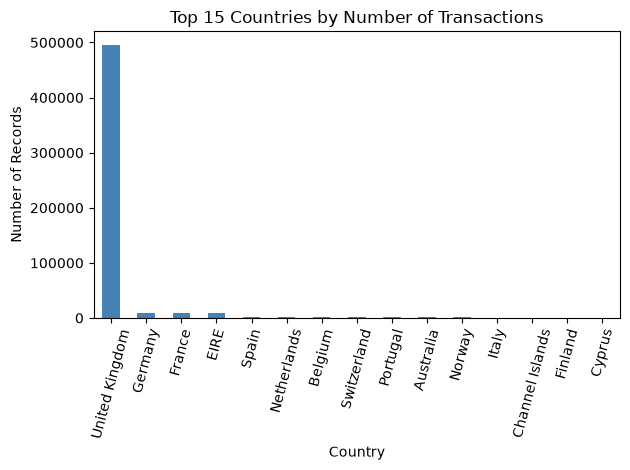

In [21]:
#Investigate missing `CustomerID` values and inspect the distribution of `Country`. Decide which analyses can be performed without customer IDs.

missing_Cst_id = df['CustomerID'].isna().sum()

print(f'Missing CustomerID: {missing_Cst_id:,}')

country_distribution = df['Country'].value_counts().head(15)

display(country_distribution)

country_distribution.plot(
         kind='bar',
         color='steelblue')
plt.title('Top 15 Countries by Number of Transactions')
plt.xlabel('Country')
plt.ylabel('Number of Records')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

---

# Part 3 — Data Cleaning & Feature Engineering (Questions 14–18)

### Q14. Define a cleaning strategy
Before changing the data, write a short plan. Explain how you will handle:
- Missing customer IDs and descriptions.
- Exact duplicate rows.
- Cancellation invoices.
- Negative quantities and zero/negative prices.
- Incorrect data types.

Do not delete returns or cancellations without explaining the analytical purpose.

### Q15. Apply cleaning steps
Create a separate DataFrame named `clean_df`. Apply your chosen cleaning strategy and document how many rows were removed or changed at each step.

### Q16. Convert data types
Ensure `InvoiceDate` is datetime and `CustomerID` is handled consistently. Convert other fields to appropriate types where justified.

### Q17. Create transaction revenue
Create a `Revenue` column using `Quantity * UnitPrice`. Explain how this calculation behaves for negative quantities and cancellation records.

### Q18. Create date features
Create `Year`, `Month`, `MonthName`, `DayName`, and `Hour` from `InvoiceDate`. Keep a chronological month order for later charts.

In [22]:
#Before modifying the dataset, I will follow the following cleaning strategy:

#1. Missing Values

#CustomerID: Preserve missing customer information or represent it as Unknown in a separate categorical representation. Avoid treating Unknown as an actual customer.

#Description: Replace missing descriptions with Unknown to preserve transaction records.

#2. Exact Duplicate Rows

#Identify and remove exact duplicate records using drop_duplicates() after inspecting them, to prevent double-counting transactions and revenue.

#3. Cancellation Invoices

#Identify cancellation invoices using InvoiceNo values starting with C.

#Create a separate cancellation indicator.

#Preserve cancellation records and analyze them separately from normal sales transactions.

#4. Negative Quantities and Non-positive Prices

#Preserve negative quantities because they may represent product returns or cancellations.

#Investigate zero UnitPrice values because they may represent free promotional products or incomplete records.

#Inspect negative UnitPrice records individually to identify potential accounting adjustments or data-entry errors.

#Avoid replacing these values with the median because doing so could distort sales and revenue calculations.

#5. Incorrect Data Types

#Convert InvoiceDate to datetime.

#Convert InvoiceNo, StockCode, and CustomerID into appropriate identifier types.

#Ensure Quantity is an integer and UnitPrice is a floating-point number.

#Convert Description and Country into appropriate string or categorical types.

# data cleaning 

In [23]:
cleaned_df = df.copy()

initial_rows = len(cleaned_df)

print(f'Original Rows before cleaning : {initial_rows:,}')

Original Rows before cleaning : 541,909


# Handle duplicates

In [24]:
duplicates_count = cleaned_df.duplicated().sum()

cleaned_df=cleaned_df.drop_duplicates().reset_index(drop=True)

print(f'Duplicates removed: {duplicates_count:,}')
print(f'Rows remaining: {len(cleaned_df):,}')


Duplicates removed: 5,268
Rows remaining: 536,641


# Handle Missings

In [ ]:
missing_description = cleaned_df['Description'].isna().sum()

cleaned_df['Description'] = cleaned_df['Description'].fillna('Unknown')

print(f'Descriptions replaced: {missing_description:,}')

# Insight: CustomerID is the most incomplete column (about 25% of rows), followed by Description (1,454 rows); the other columns are complete.

Descriptions replaced: 1,454


In [26]:
missing_IDs = cleaned_df['CustomerID'].isna().sum()

# CustomerID
cleaned_df['CustomerID']  = cleaned_df['CustomerID'].astype('Int64').astype('string')
cleaned_df['HasCustomer'] = cleaned_df['CustomerID'].notna()
cleaned_df['CustomerID']  = cleaned_df['CustomerID'].fillna('Guest')

print(f'IDs replaced: {missing_IDs:,}')

IDs replaced: 135,037


# Cancellation invoices

In [27]:
cleaned_df['Is_Cancellation'] = (cleaned_df['InvoiceNo'].astype(str).str.startswith('C'))

print(cleaned_df['Is_Cancellation'].value_counts())
print('Cancellation rows:', cleaned_df['Is_Cancellation'].sum())

Is_Cancellation
False    527390
True       9251
Name: count, dtype: int64
Cancellation rows: 9251


In [28]:
cleaned_df[(cleaned_df['Is_Cancellation'] == False) & (cleaned_df['Quantity'] <0)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,HasCustomer,Is_Cancellation
2362,536589,21777,Unknown,-10,2010-12-01 16:50:00,0.00,Guest,United Kingdom,False,False
4286,536764,84952C,Unknown,-38,2010-12-02 14:42:00,0.00,Guest,United Kingdom,False,False
7086,536996,22712,Unknown,-20,2010-12-03 15:30:00,0.00,Guest,United Kingdom,False,False
7087,536997,22028,Unknown,-20,2010-12-03 15:30:00,0.00,Guest,United Kingdom,False,False
7088,536998,85067,Unknown,-6,2010-12-03 15:30:00,0.00,Guest,United Kingdom,False,False
...,...,...,...,...,...,...,...,...,...,...
530105,581210,23395,check,-26,2011-12-07 18:36:00,0.00,Guest,United Kingdom,False,False
530107,581212,22578,lost,-1050,2011-12-07 18:38:00,0.00,Guest,United Kingdom,False,False
530108,581213,22576,check,-30,2011-12-07 18:38:00,0.00,Guest,United Kingdom,False,False
531680,581226,23090,missing,-338,2011-12-08 09:56:00,0.00,Guest,United Kingdom,False,False


In [29]:
cleaned_df['HasCustomer'].value_counts()

HasCustomer
True     401604
False    135037
Name: count, dtype: int64

# unusual quantities and prices

In [30]:
negative_quantity = (cleaned_df['Quantity'] < 0).sum()
zero_quantity = (cleaned_df['Quantity'] == 0).sum()

zero_price = (cleaned_df['UnitPrice'] == 0).sum()
negative_price = (cleaned_df['UnitPrice'] < 0).sum()

print('Negative Quantity:', negative_quantity)
print('Zero Quantity:', zero_quantity)
print('Zero UnitPrice:', zero_price)
print('Negative UnitPrice:', negative_price)

Negative Quantity: 10587
Zero Quantity: 0
Zero UnitPrice: 2510
Negative UnitPrice: 2


#  Date features

In [31]:
cleaned_df['Year']  = cleaned_df.InvoiceDate.dt.year
cleaned_df['Month'] = cleaned_df.InvoiceDate.dt.to_period('M').astype(str)
cleaned_df['Hour']  = cleaned_df.InvoiceDate.dt.hour

In [32]:
cleaned_df['day_name']  = cleaned_df.InvoiceDate.dt.day_name()
cleaned_df['month_name']  = cleaned_df.InvoiceDate.dt.month_name()

In [33]:
cleaned_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,HasCustomer,Is_Cancellation,Year,Month,Hour,day_name,month_name
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December


In [34]:
cleaned_df['Revenue'] = cleaned_df['UnitPrice'] * cleaned_df['Quantity']

cleaned_df['Revenue']

0        15.30
1        20.34
2        22.00
3        20.34
4        20.34
          ... 
536636   10.20
536637   12.60
536638   16.60
536639   16.60
536640   14.85
Name: Revenue, Length: 536641, dtype: float64

In [35]:
cleaned_df.dtypes

InvoiceNo                     str
StockCode                     str
Description                   str
Quantity                    int64
InvoiceDate        datetime64[us]
UnitPrice                 float64
CustomerID                 string
Country                       str
HasCustomer                  bool
Is_Cancellation              bool
Year                        int32
Month                         str
Hour                        int32
day_name                      str
month_name                    str
Revenue                   float64
dtype: object

In [ ]:
# Base table for the business analysis: real product sales only
sales = cleaned_df[(~cleaned_df.Is_Cancellation) & (cleaned_df.Quantity > 0) &
                   (cleaned_df.UnitPrice > 0)].copy()
rows_before = len(sales)

# 1) Non-product codes (postage, manual adjustments, fees, bank charges...) are not products
non_product = ['DOT', 'POST', 'M', 'D', 'C2', 'AMAZONFEE', 'B', 'S', 'BANK CHARGES', 'PADS']
sales = sales[~sales['StockCode'].isin(non_product)]
print('Non-product rows removed:', rows_before - len(sales))

# 2) Orders that were fully cancelled minutes later by the same customer:
# 581483 (80,995 units, reversed by C581484) and 541431 (74,215 units, reversed by C541433)
reversed_invoices = ['581483', '541431']
rows_before = len(sales)
sales = sales[~sales['InvoiceNo'].isin(reversed_invoices)].reset_index(drop=True)
print('Reversed-order rows removed:', rows_before - len(sales))

print('Rows in sales:', f'{len(sales):,}')
sales

Non-product rows removed: 2309
Reversed-order rows removed: 2
Rows in sales: 522,567


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,HasCustomer,Is_Cancellation,Year,Month,Hour,day_name,month_name,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,20.34
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
522562,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,True,False,2011,2011-12,12,Friday,December,10.20
522563,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,True,False,2011,2011-12,12,Friday,December,12.60
522564,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,True,False,2011,2011-12,12,Friday,December,16.60
522565,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,True,False,2011,2011-12,12,Friday,December,16.60


---

# Part 4 — Pandas Business Analysis (Questions 19–24)

### Q19. Top products by quantity
Find the 10 products with the highest total quantity sold. Exclude or separately report returns so that sales and returns are not mixed.

### Q20. Top products by revenue
Find the 10 products with the highest total revenue. Compare the ranking with Q19. Are the same products at the top?

### Q21. Country performance
Calculate total revenue, number of invoices, and average invoice value for each country. Rank countries by revenue and compare the United Kingdom with other countries.

### Q22. Monthly revenue trend
Aggregate revenue by month and year. Which month has the highest revenue? Which month has the lowest? Use a chronological index.

### Q23. Customer analysis
Calculate total spend, number of invoices, and average spend per customer. Identify the top 10 customers by total spend. State how you handled missing CustomerID values.

### Q24. Invoice-level analysis
Group records by `InvoiceNo` to calculate invoice value, number of distinct products, and total quantity. Identify the largest invoices and investigate whether cancellations affect the ranking.

 # Q1 Top Products by quantity

In [37]:
sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,HasCustomer,Is_Cancellation,Year,Month,Hour,day_name,month_name,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,True,False,2010,2010-12,8,Wednesday,December,20.34


In [38]:
top_products = sales.groupby(['StockCode','Description'] )['Quantity'].sum().sort_values(ascending=False).head(10).reset_index()

top_products.columns = ['StockCode', 'Product', 'Total Quantity']

display(top_products)

,StockCode,Product,Total Quantity
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
1,85099B,JUMBO BAG RED RETROSPOT,48371
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580
3,22197,POPCORN HOLDER,36749
4,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
5,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
6,23084,RABBIT NIGHT LIGHT,30739
7,22492,MINI PAINT SET VINTAGE,26633
8,22616,PACK OF 12 LONDON TISSUES,26119
9,21977,PACK OF 60 PINK PAISLEY CAKE CASES,24820


# Q2 top Products by Revenue

In [39]:
# Find the 10 products with the highest total revenue. Compare the ranking with Q19. Are the same products at the top?

top_products_revenue = sales.groupby(['StockCode' , 'Description'])['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

top_products_revenue.columns = ['StockCode', 'Product', 'Total Revenue']

display(top_products_revenue)

# not the same products at the top comparing to the previous question

,StockCode,Product,Total Revenue
0,22423,REGENCY CAKESTAND 3 TIER,"174,156.54"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,284.24"
2,47566,PARTY BUNTING,"99,445.23"
3,85099B,JUMBO BAG RED RETROSPOT,"94,159.81"
4,23084,RABBIT NIGHT LIGHT,"66,870.03"
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,875.59"
6,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,927.62"
7,79321,CHILLI LIGHTS,"54,096.36"
8,23298,SPOTTY BUNTING,"42,513.48"
9,22386,JUMBO BAG PINK POLKADOT,"42,401.01"


### Q21. Country performance
Calculate total revenue, number of invoices, and average invoice value for each country. Rank countries by revenue and compare the United Kingdom with other countries.

In [40]:
country_performance = (
    sales.groupby('Country')
    .agg(Total_revenue = ('Revenue' , 'sum'),
         Total_invoice = ('InvoiceNo' , 'nunique')
         ))

country_performance['average_invoice_value'] = (
    country_performance['Total_revenue'] / country_performance['Total_invoice']
)

country_performance = (
    country_performance
    .sort_values('Total_revenue', ascending=False)
    .reset_index()
)

country_performance.insert(
    0,
    'Revenue_Rank',
    range(1, len(country_performance) + 1)
)


display(country_performance.head(20))

,Revenue_Rank,Country,Total_revenue,Total_invoice,average_invoice_value
0,1,United Kingdom,"8,479,478.83",17899,473.74
1,2,Netherlands,"283,889.34",93,"3,052.57"
2,3,EIRE,"270,850.86",282,960.46
3,4,Germany,"205,381.15",443,463.61
4,5,France,"184,493.00",382,482.97
5,6,Australia,"138,103.81",56,"2,466.14"
6,7,Spain,"55,706.56",88,633.03
7,8,Switzerland,"53,065.60",50,"1,061.31"
8,9,Japan,"37,416.37",19,"1,969.28"
9,10,Belgium,"36,927.34",98,376.81


# Compare the UK with other countries

In [41]:
UK_performance = country_performance[
    country_performance['Country'] == 'United Kingdom'
]
other_countries = country_performance[
    country_performance['Country'] != 'United Kingdom'
]

display(UK_performance)

print('Average Revenue for Other Countries : ' , other_countries['Total_revenue'].mean() )
print('Average Invoice Value for Other Countries : ' , other_countries['average_invoice_value'].mean() )

,Revenue_Rank,Country,Total_revenue,Total_invoice,average_invoice_value
0,1,United Kingdom,"8,479,478.83",17899,473.74


Average Revenue for Other Countries :  41156.09864864865
Average Invoice Value for Other Countries :  900.4969979775668


### Q22. Monthly revenue trend
Aggregate revenue by month and year. Which month has the highest revenue? Which month has the lowest? Use a chronological index.

In [42]:
sales.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'HasCustomer', 'Is_Cancellation',
       'Year', 'Month', 'Hour', 'day_name', 'month_name', 'Revenue'],
      dtype='str')

In [43]:
months_order = ['January', 'February', 'March', 'April', 'May', 'June',
                'July', 'August', 'September', 'October', 'November', 'December']

sales['month_name'] = pd.Categorical(
    sales['month_name'],
    categories=months_order,
    ordered=True
)
monthly_revenue = sales.groupby(['month_name','Year'],observed=True)['Revenue'].sum().reset_index().sort_values(['Year', 'month_name'])


highest_month = monthly_revenue.loc[monthly_revenue['Revenue'].idxmax()]
lowest_month = monthly_revenue.loc[monthly_revenue['Revenue'].idxmin()]

print('Highest Revenue Month:')
print(highest_month)

print('\nLowest Revenue Month:')
print(lowest_month)

Highest Revenue Month:
month_name       November
Year                 2011
Revenue      1,452,115.98
Name: 10, dtype: object

Lowest Revenue Month:
month_name     December
Year               2011
Revenue      446,029.65
Name: 12, dtype: object


#  Q23. Customer analysis
Calculate total spend, number of invoices, and average spend per customer. Identify the top 10 customers by total spend. State how you handled missing CustomerID values.

In [44]:
# 'Guest' = rows without a CustomerID (not a real customer), so they are excluded from the customer ranking
cst_analysis_top_10 = sales[sales['HasCustomer']].groupby('CustomerID').agg(
    Total_revenue = ('Revenue' , 'sum'),
    Total_invoices = ('InvoiceNo','nunique'),
    avg_spent_per_cst = ('Revenue' , 'mean')

).sort_values(by='Total_revenue',ascending=False).head(10).reset_index()
cst_analysis_top_10

,CustomerID,Total_revenue,Total_invoices,avg_spent_per_cst
0,14646,"279,138.02",72,135.50
1,18102,"259,657.30",60,602.45
2,17450,"194,390.79",46,578.54
3,14911,"136,161.83",198,24.38
4,12415,"124,564.53",20,174.70
5,14156,"116,560.08",54,84.34
6,17511,"91,062.38",31,94.56
7,16029,"72,708.09",62,302.95
8,16684,"66,653.56",28,240.63
9,13694,"65,039.62",50,114.51


### Q24. Invoice-level analysis
Group records by `InvoiceNo` to calculate invoice value, number of distinct products, and total quantity. Identify the largest invoices and investigate whether cancellations affect the ranking.

In [45]:
invoice_analysis=sales.groupby('InvoiceNo').agg(
    Invoice_value = ('Revenue' , 'sum'),
    Distinct_Products = ('StockCode','nunique'),
    Total_Quantity = ('Quantity' , 'sum')
).reset_index().sort_values('Invoice_value',ascending=False)

display(invoice_analysis)

,InvoiceNo,Invoice_value,Distinct_Products,Total_Quantity
16753,574941,"52,940.94",101,14149
17402,576365,"50,653.91",99,13956
8631,556444,"38,970.00",1,60
13420,567423,"31,698.16",12,12572
8837,556917,"22,775.93",138,15049
...,...,...,...,...
10288,560217,0.79,1,1
1880,540833,0.65,1,1
2622,542736,0.55,1,1
1350,539441,0.42,1,1


---

# Part 5 — Matplotlib Visualizations 

### Q25. Product revenue comparison
Create a horizontal bar chart for the top 10 products by revenue. Include a clear title, axis labels, readable product labels, and an appropriate figure size.

### Q26. Monthly sales trend
Create a line chart of monthly revenue. Add markers, grid lines, axis labels, and a title. Ensure the months are sorted chronologically and explain the main trend.

# Product Revenue Comparison

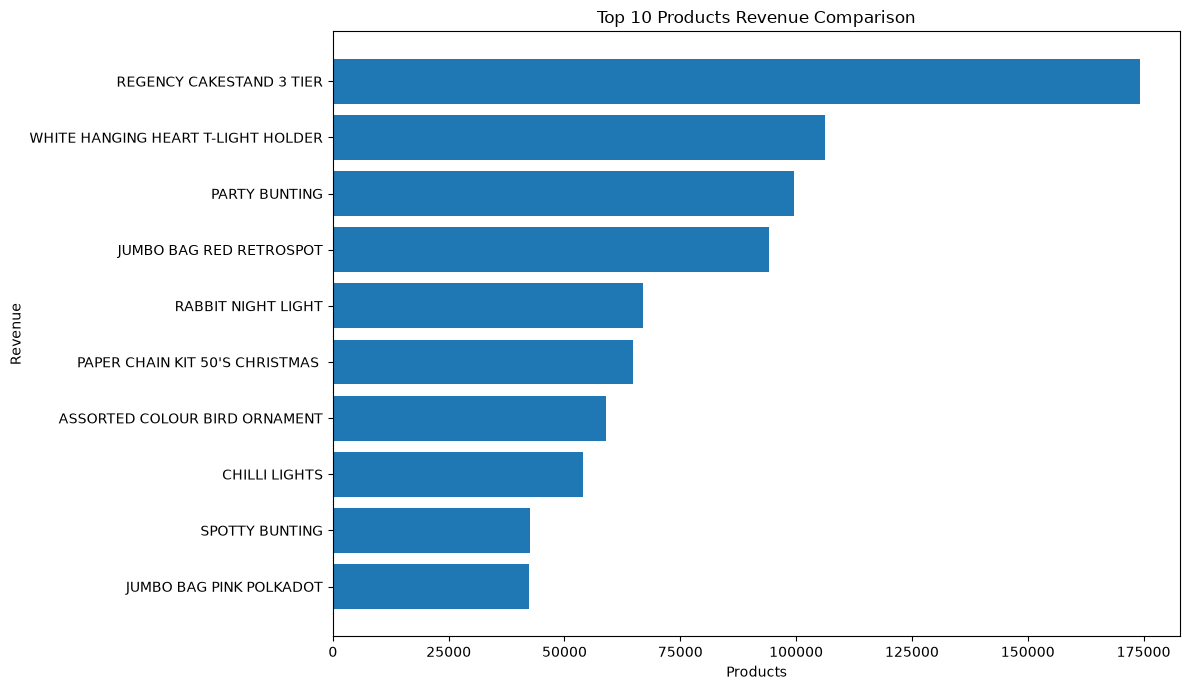

In [46]:
plt.figure(figsize=(12,7))


top_products = sales.groupby('Description' )['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

top_products.columns = [ 'Product', 'Total_Revenue']



plt.barh(top_products['Product'],
            top_products['Total_Revenue']
        )

plt.title('Top 10 Products Revenue Comparison')
plt.xlabel('Products')
plt.ylabel('Revenue')
plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

# Monthly Sales Trend

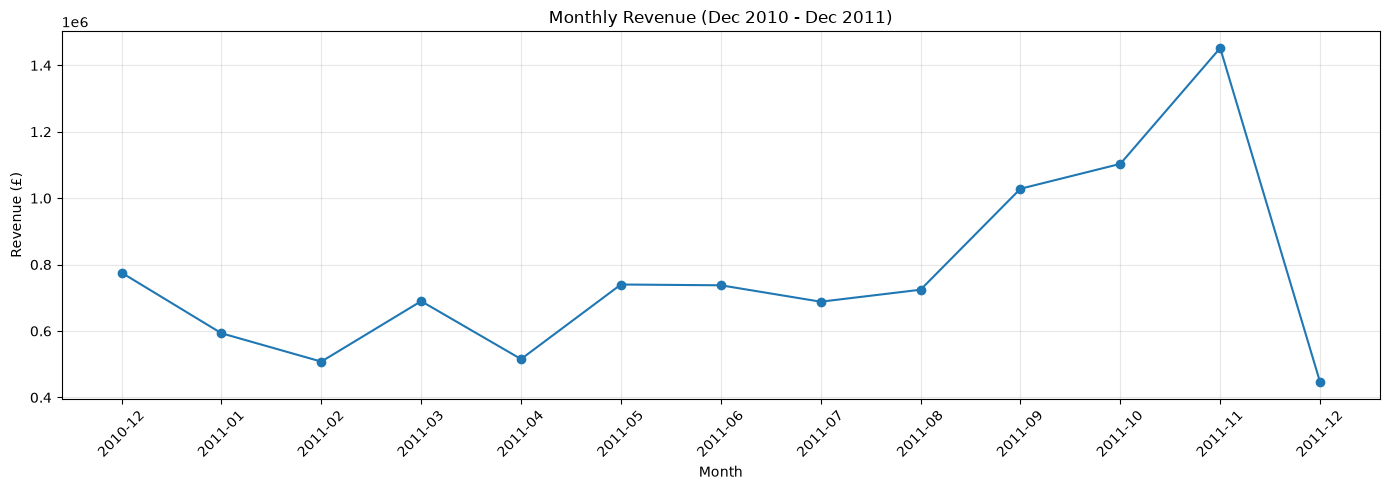

In [47]:
# Group by Month ('YYYY-MM'), so Dec 2010 and Dec 2011 stay separate and the order is chronological
monthly_revenue = sales.groupby('Month', as_index=False)['Revenue'].sum()

plt.figure(figsize=(14,5))
plt.plot(monthly_revenue['Month'], monthly_revenue['Revenue'], marker='o')
plt.title('Monthly Revenue (Dec 2010 - Dec 2011)')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Note: December 2011 is a partial month (the data ends on 9 December 2011)

---

# Part 6 — Seaborn Visualizations (Questions 27–28)

### Q27. Revenue distribution and outliers
Use a Seaborn boxplot to visualize the distribution of invoice values or transaction revenue. Handle extreme values thoughtfully: show the full distribution first, then optionally create a second view with a justified range. Explain what the outliers may represent.

### Q28. Correlation and final interactive dashboard chart
Choose suitable numeric features and create a Seaborn correlation heatmap with annotations. Then create at least one Plotly interactive chart (for example, monthly revenue by country or top products by revenue) with a meaningful hover tooltip. Write two insights from the visualizations.




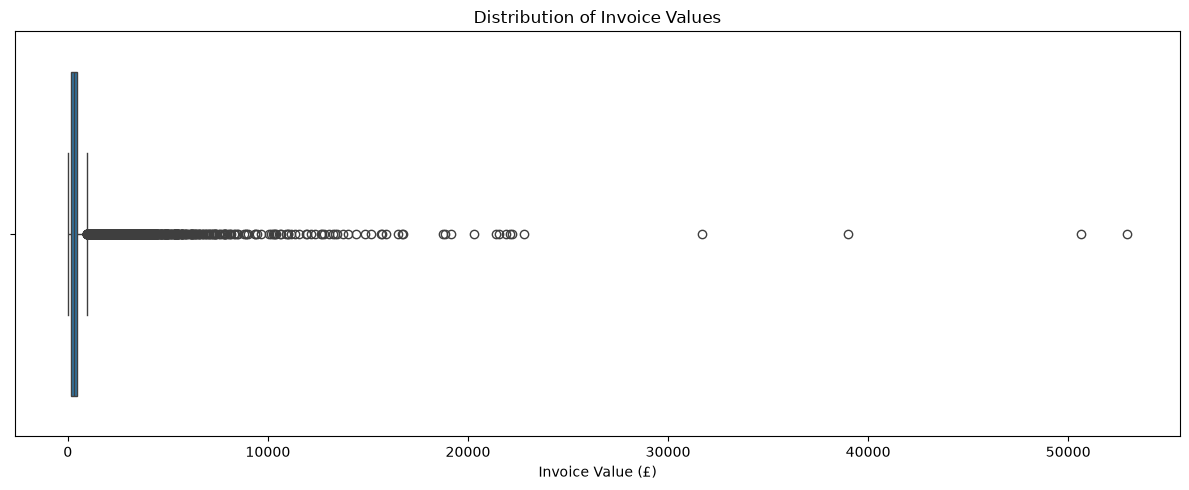

In [48]:
plt.figure(figsize=(12,5))

sns.boxplot(
    x = invoice_analysis['Invoice_value']
)

plt.title('Distribution of Invoice Values')
plt.xlabel('Invoice Value (£)')
plt.tight_layout()

plt.show()

In [49]:
Q1 = invoice_analysis['Invoice_value'].quantile(0.25)
Q3 = invoice_analysis['Invoice_value'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = invoice_analysis[
    (invoice_analysis['Invoice_value'] < lower_bound) |
    (invoice_analysis['Invoice_value'] > upper_bound)
]

print('Number of Outlier Invoices:', len(outliers))

display(
    outliers.sort_values(
        'Invoice_value',
        ascending=False
    ).head(10)
)

Number of Outlier Invoices: 1801


,InvoiceNo,Invoice_value,Distinct_Products,Total_Quantity
16753,574941,"52,940.94",101,14149
17402,576365,"50,653.91",99,13956
8631,556444,"38,970.00",1,60
13420,567423,"31,698.16",12,12572
8837,556917,"22,775.93",138,15049
15542,572209,"22,206.00",7,1920
13412,567381,"22,104.80",12,6760
11782,563614,"21,880.44",97,12196
5968,550461,"21,535.90",5,9014
5019,548203,"21,389.60",138,5963


### Q28. Correlation and final interactive dashboard chart
Choose suitable numeric features and create a Seaborn correlation heatmap with annotations. Then create at least one Plotly interactive chart (for example, monthly revenue by country or top products by revenue) with a meaningful hover tooltip. Write two insights from the visualizations.

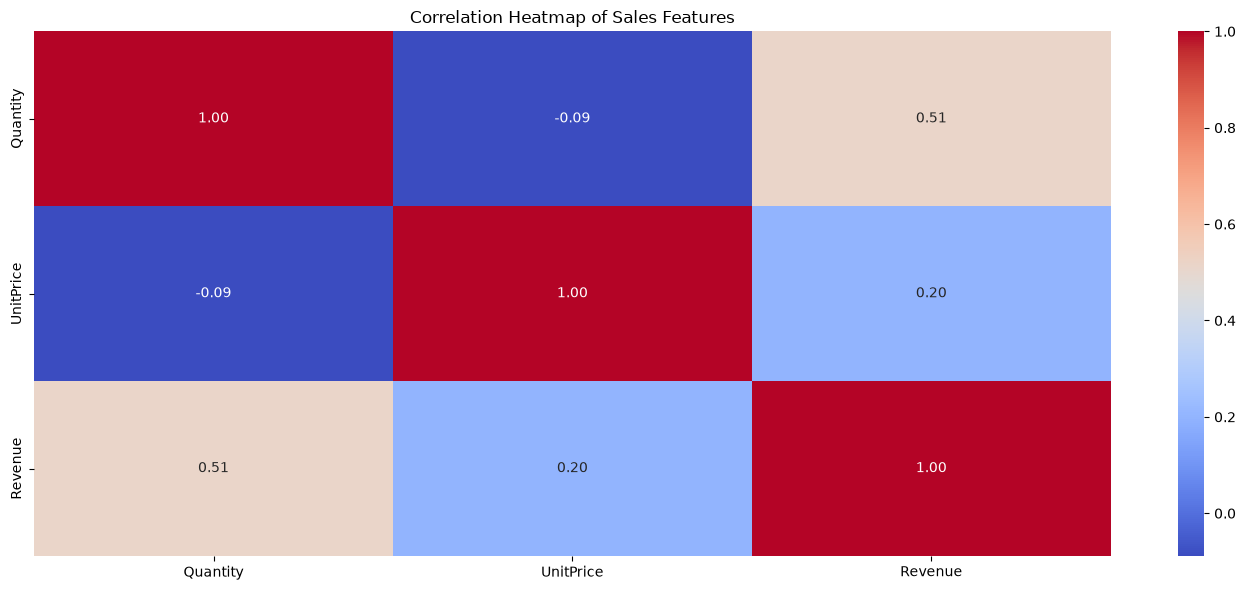

In [50]:
correlation_data = sales[['Quantity', 'UnitPrice', 'Revenue']]
correlation_matrix = correlation_data.corr()

plt.figure(figsize=(14, 6))

sns.heatmap(
    correlation_matrix,
    annot= True,
    cmap = 'coolwarm',
    fmt = '.2f'
)
plt.title('Correlation Heatmap of Sales Features' )

plt.tight_layout()
plt.show()

In [51]:
top_products = (
    sales.groupby('StockCode').agg(
        Product=('Description', 'first'),
        Total_Revenue = ('Revenue', 'sum'),
        Total_Quantity = ('Quantity', 'sum'),
        Invoice_Count = ('InvoiceNo', 'nunique')
    ).round(2)
).sort_values('Total_Revenue', ascending=False).head(10).reset_index()


display(top_products)


fig=px.bar(top_products.sort_values('Total_Revenue'),
       x = 'Total_Revenue',
       y='Product',
       orientation = 'h',
       custom_data=['Total_Quantity', 'Invoice_Count'],
        title='Top 10 Products by Revenue',
        labels={
        'Total_Revenue': 'Total Revenue (£)',
        'Product': 'Product'},
        text = 'Total_Revenue',
        color='Total_Revenue',
        hover_name = 'Invoice_Count'
       )

fig.show()

,StockCode,Product,Total_Revenue,Total_Quantity,Invoice_Count
0,22423,REGENCY CAKESTAND 3 TIER,"174,156.54",13851,1988
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,462.75",37641,2198
2,47566,PARTY BUNTING,"99,445.23",18283,1685
3,85099B,JUMBO BAG RED RETROSPOT,"94,159.81",48371,2089
4,23084,RABBIT NIGHT LIGHT,"66,870.03",30739,994
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,875.59",19329,1160
6,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,927.62",36362,1455
7,79321,CHILLI LIGHTS,"54,096.36",10302,661
8,22502,PICNIC BASKET WICKER SMALL,"51,408.77",1937,463
9,22197,SMALL POPCORN HOLDER,"51,334.47",56898,1392


In [ ]:
## Final Project Conclusion

# 1. Three most important data-quality issues
# - 5,268 duplicate rows, and about 25% of rows with no CustomerID (plus 1,454 missing descriptions).
# - Non-product codes (postage, manual adjustments, fees) mixed in with real products.
# - Cancellations (`C` invoices) and two huge orders that were fully cancelled minutes later, which distorted the quantity and revenue rankings.

# 2. Cleaning decisions and why
# - Dropped exact duplicates so no order is counted twice.
# - Kept rows without a CustomerID as "Guest" with a `HasCustomer` flag, so revenue is not lost but Guest is excluded from customer rankings.
# - Separated cancellations into `Is_Cancellation`, and built a `sales` table with only real product sales (positive quantity and price, no non-product codes, no reversed orders).

# 3. Top product and country by revenue
# - Top product: Regency Cakestand 3 Tier (about £174K). Top country: United Kingdom (about 85% of revenue).

# 4. Important trend
# - Revenue peaks in Q4: November (about £1.45M) is roughly 2.9x February, and September to November produce about 40% of January to November revenue.



## Final Project Conclusion

Write a concise conclusion containing:

1. The three most important data-quality issues you discovered.
2. The cleaning decisions you made and why.
3. The top product and top country by revenue.
4. One important trend in sales, customers, or returns.
5. Three actionable business recommendations.

## Publishing and Submission

- Restart the kernel and run all cells from top to bottom.
- Make sure your notebook contains no errors and all charts are visible.
- Publish the completed notebook publicly on Kaggle or GitHub.
- Publish a LinkedIn post describing your **3 most interesting findings** and include the notebook link.
- Submit both links: **Notebook URL** and **LinkedIn post URL**.
